# ML-SFQED demo: surrogate, inference and model comparison

This notebook walks through what the pipeline does, using the trained models shipped in `models/`.

1. **Surrogate**: predict Ptarmigan's outputs for a collision, in milliseconds, with 90% intervals.
2. **Physics with the surrogate**: how energy loss and spectral sharpness (P70) depend on the laser strength, the timing and alignment, and the radiation-reaction model.
3. **Propagating beam uncertainty**: many incoming beams through one collision.
4. **Inference on a shot**: recover the laser strength from an outgoing spectrum's mean energy and P70, and compare the three radiation-reaction models.
5. *Optional, needs the Los et al. data* (`bash scripts/fetch_los2024.sh`): the same on a real 2021 collision shot.
6. *Optional, needs the Gemini data* (Zenodo 7510352 in `data/raw/`): the Stage 1 beam model predicting a held-out shot's spectrum.

Sections 1–4 need only the repository (`pip install -e .`). Everything runs on a laptop CPU.

In [1]:
import json
import logging
import time
import warnings

logging.getLogger("emcee").setLevel(logging.ERROR)   # chain-length notes; chains here are 8,000 steps
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from mlsfqed.surrogate.api import Surrogate

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
COL = {"stochastic": "#2b6cb0", "continuous": "#8a5cc2", "classical": "#d9822b"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

b = np.load(ROOT / "models" / "example_beams.npz")
E, beams = b["E_MeV"], b["dWdE_J_per_GeV"]          # six measured Gemini spectra, dW/dE in J/GeV
print(beams.shape, "example beams on an energy grid of", len(E), "points")

(6, 200) example beams on an energy grid of 200 points


## 1. Predict a collision with the surrogate

`Surrogate.load(model)` loads one of the trained MLP ensembles. `predict(beam, **parameters)` takes an incoming spectrum and any of the 9 collision parameters (the rest default to the nominal Gemini 2021 set-up) and returns one row per collision: each Ptarmigan observable with its calibrated 90% interval (`_lo`, `_hi`).

In [2]:
s = Surrogate.load("stochastic")
print("outputs:", s.targets)
print("training ranges:", s.ranges)

df = s.predict(beams[0], a0=12.0, dz_um=0.0, r_offset_um=0.0)
cols = ["loss_window_MeV", "e_P70", "g_crit_MeV", "log_g_number_per_e"]
df[[c + sfx for c in cols for sfx in ("_lo", "", "_hi")]].T.rename(columns={0: "a0 = 12, head-on at focus"}).round(3)

outputs: ['loss_MeV', 'loss_window_MeV', 'e_std_MeV', 'e_P70', 'log_g_number_per_e', 'log_g_energy_per_e', 'g_crit_MeV', 'g_theta_x_rms_mrad', 'g_theta_y_rms_mrad']
training ranges: {'a0': (5, 20), 'waist_um': (2, 3), 'fwhm_fs': (35, 55), 'r_offset_um': (0, 5), 'dz_um': (-250, 250), 'radius_um': (0.5, 2), 'length_um': (1, 10), 'div_mrad': (1, 4)}


,"a0 = 12, head-on at focus"
loss_window_MeV_lo,53.922
loss_window_MeV,61.719
loss_window_MeV_hi,69.516
e_P70_lo,1.570
e_P70,1.787
e_P70_hi,2.005
g_crit_MeV_lo,28.075
g_crit_MeV,29.307
g_crit_MeV_hi,30.539
log_g_number_per_e_lo,0.857


## 2. Physics from the surrogate

**Laser strength and radiation-reaction model.** One incoming beam, head-on at focus, a0 from 5 to 20, for the three models (the three surrogates trained on the same 4,096 collisions). Classical radiation reaction removes the most energy. It also sharpens the peak (P70 rises well above the incoming beam's), and continuous emission does the same more weakly; stochastic emission adds a random component to each electron's loss, so the peak stays broader, below the incoming P70 up to a0 ≈ 15. That difference in P70 is what separates the models in the data.

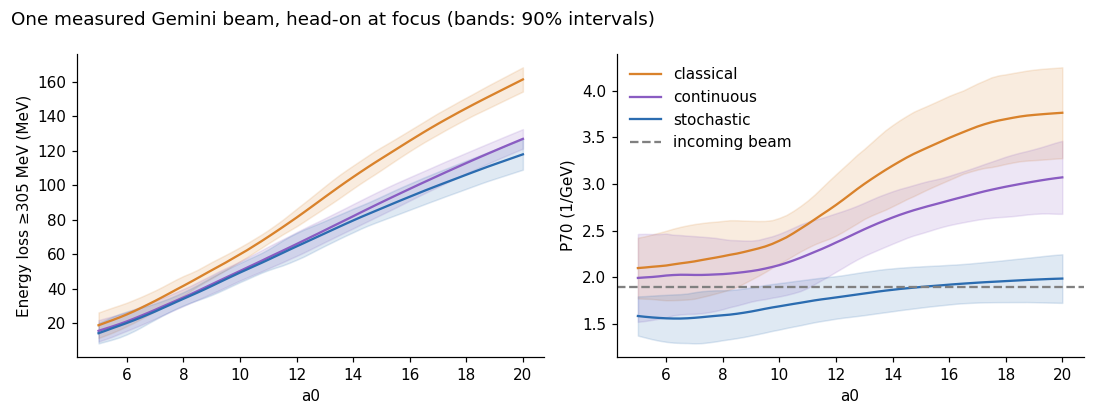

In [3]:
a0 = np.linspace(5, 20, 61)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for mdl in ("classical", "continuous", "stochastic"):
    sm = Surrogate.load("stochastic_4096" if mdl == "stochastic" else mdl)
    d = sm.predict(beams[0], a0=a0)
    for k, (c, lab) in enumerate((("loss_window_MeV", "Energy loss ≥305 MeV (MeV)"), ("e_P70", "P70 (1/GeV)"))):
        ax[k].plot(a0, d[c], color=COL[mdl], label=mdl)
        ax[k].fill_between(a0, d[c + "_lo"], d[c + "_hi"], color=COL[mdl], alpha=0.15)
        ax[k].set(xlabel="a0", ylabel=lab)
from mlsfqed.simulation.ptarmigan import p70

ax[1].axhline(p70(E[E >= 305], (beams[0] / E)[E >= 305], 0), color="grey", ls="--", label="incoming beam")
ax[1].legend(frameon=False)
fig.suptitle("One measured Gemini beam, head-on at focus (bands: 90% intervals)", x=0.01, ha="left")
fig.tight_layout()

**Timing and alignment.** The same beam at a0 = 15: energy loss against the longitudinal offset from focus and the sideways offset. The field the electrons see falls off quickly with either, which is why only the *effective* a0 can be inferred from the energy loss.

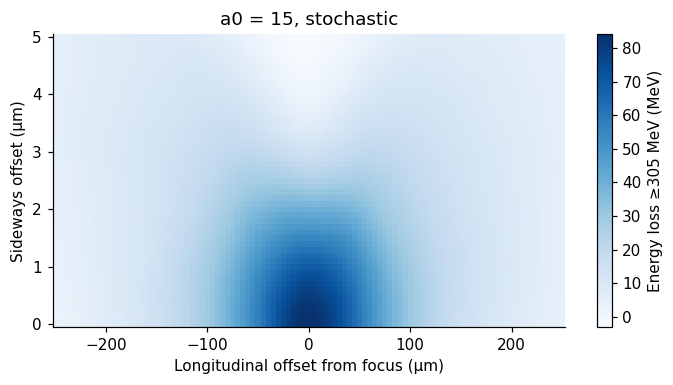

In [4]:
dz = np.linspace(-250, 250, 101)
r = np.linspace(0, 5, 51)
DZ, R = np.meshgrid(dz, r)
d = s.predict(beams[0], a0=15.0, dz_um=DZ.ravel(), r_offset_um=R.ravel())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.pcolormesh(DZ, R, d.loss_window_MeV.values.reshape(DZ.shape), shading="auto", cmap="Blues")
fig.colorbar(im, label="Energy loss ≥305 MeV (MeV)")
ax.set(xlabel="Longitudinal offset from focus (µm)", ylabel="Sideways offset (µm)", title="a0 = 15, stochastic")
fig.tight_layout()

**Speed.** The grid above is 5,151 collisions. Ptarmigan needs about 5 CPU-seconds per collision at 5,000 macro-electrons.

In [5]:
n = 100_000
t0 = time.time()
s.predict(beams[0], a0=np.random.default_rng(0).uniform(5, 20, n))
dt = time.time() - t0
print(f"{n:,} collisions in {dt:.2f} s  ->  {dt / n * 1e6:.1f} µs each; Ptarmigan would need ~{n * 5 / 3600:.0f} CPU-hours")

100,000 collisions in 0.24 s  ->  2.4 µs each; Ptarmigan would need ~139 CPU-hours


## 3. Propagating the incoming-beam uncertainty

On a collision shot the incoming spectrum is not measured, only predicted, so the prediction's uncertainty has to be carried through. Here the six example spectra stand in for six draws of an uncertain beam: the same collision gives a spread of outcomes, and that spread enters the likelihood.

In [6]:
d = s.predict(beams, a0=12.0)
print(d[["beam_mean_window_MeV", "loss_window_MeV", "out_mean_window_MeV", "e_P70"]].round(2).to_string())
print(f"\nspread over beams: outgoing mean energy ±{d.out_mean_window_MeV.std():.1f} MeV, P70 ±{d.e_P70.std():.2f}")

   beam_mean_window_MeV  loss_window_MeV  out_mean_window_MeV  e_P70
0                555.20            61.72               493.48   1.79
1                567.46            64.81               502.65   2.10
2                577.72            69.81               507.91   1.94
3                584.35            70.25               514.10   1.78
4                604.85            76.52               528.33   1.67
5                646.97            88.05               558.92   1.69

spread over beams: outgoing mean energy ±23.4 MeV, P70 ±0.16


## 4. Inference and model comparison on a simulated shot

A toy shot with known answers: the stochastic surrogate's prediction at a0 = 14, 40 µm from focus, taken as the measurement (without added noise, so the result is not a matter of a lucky draw), with the likelihood assuming the usual measurement errors of 10 MeV on the mean energy and 5% on P70. The inference sees only the outgoing mean energy and P70 and the incoming beam, and samples a0, the timing offset and the bunch length with `emcee`.

(The recovery tests in `results/` do the same with held-out **Ptarmigan** runs, so that surrogate error is part of the test.)

true effective a0 10.85;  'measured' mean 507.8 MeV, P70 1.92


MCMC 11 s, acceptance 0.48
a0 (peak)     13.21  90% [10.58, 18.99]   truth 14.00
effective a0  11.30  90% [ 9.18, 13.36]   truth 10.85


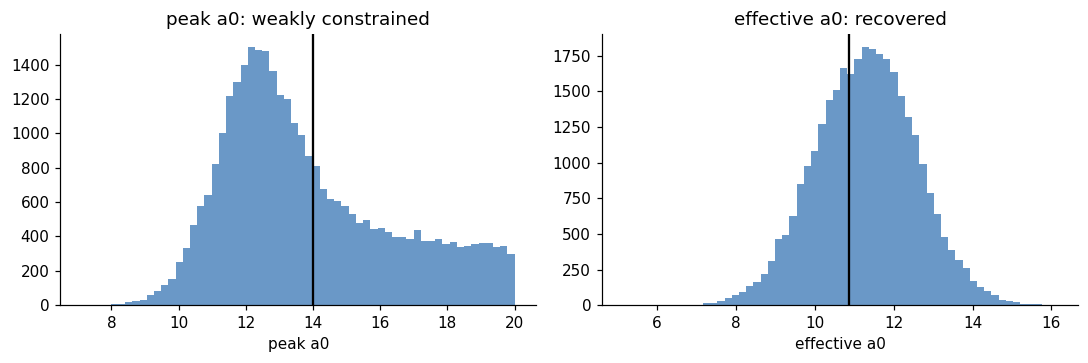

In [7]:
from mlsfqed.inference.posterior import ShotPosterior, run_mcmc

truth = {"a0": 14.0, "dz_um": 40.0, "length_um": 5.0}
t = Surrogate.load("stochastic_4096").predict(beams[2], **truth)
obs_mean, obs_p70 = t.out_mean_window_MeV[0], t.e_P70[0]
print(f"true effective a0 {t.a0_eff_est[0]:.2f};  'measured' mean {obs_mean:.1f} MeV, P70 {obs_p70:.2f}")

post = ShotPosterior(s.model, beams[2:3], obs_mean, obs_p70, meas_sd_mean=10.0, dz_prior="focus")
t0 = time.time()
chain, diag = run_mcmc(post, nwalkers=32, nsteps=8000, burn=3000)
a_eff = post.a0_eff(chain)
print(f"MCMC {time.time() - t0:.0f} s, acceptance {diag['acceptance']:.2f}")
for name, x, tr in (("a0 (peak)", chain[:, 0], truth["a0"]), ("effective a0", a_eff, t.a0_eff_est[0])):
    lo, med, hi = np.percentile(x, [5, 50, 95])
    print(f"{name:13s} {med:5.2f}  90% [{lo:5.2f}, {hi:5.2f}]   truth {tr:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(chain[:, 0], 60, color=COL["stochastic"], alpha=0.7); ax[0].axvline(truth["a0"], color="k")
ax[0].set(xlabel="peak a0", title="peak a0: weakly constrained")
ax[1].hist(a_eff, 60, color=COL["stochastic"], alpha=0.7); ax[1].axvline(t.a0_eff_est[0], color="k")
ax[1].set(xlabel="effective a0", title="effective a0: recovered")
fig.tight_layout()

**Which radiation-reaction model fits?** The evidence of each model (Monte Carlo over the prior), with both observables and with the mean energy alone. A positive log Bayes factor favours the model over classical. With the mean energy alone the models are nearly indistinguishable, because a different a0 compensates; P70 separates them.

In [8]:
logZ = {}
for mdl in ("stochastic", "continuous", "classical"):
    sm = Surrogate.load("stochastic_4096" if mdl == "stochastic" else mdl)
    p = ShotPosterior(sm.model, beams[2:3], obs_mean, obs_p70, meas_sd_mean=10.0, dz_prior="focus")
    logZ[mdl] = {"mean + P70": p.log_evidence(n=40000, seed=1, use=(0, 1))[0],
                 "mean only": p.log_evidence(n=40000, seed=1, use=(0,))[0]}
for obs in ("mean + P70", "mean only"):
    print(f"{obs:11s}  log BF vs classical:  stochastic {logZ['stochastic'][obs] - logZ['classical'][obs]:+.2f}   "
          f"continuous {logZ['continuous'][obs] - logZ['classical'][obs]:+.2f}")

mean + P70   log BF vs classical:  stochastic +4.02   continuous +0.45
mean only    log BF vs classical:  stochastic +0.14   continuous +0.15


## 5. Optional: a real 2021 collision shot

Needs the Los et al. public data (`bash scripts/fetch_los2024.sh`, kept local). Shot 4 (their shot 5), with the 100 published incoming-beam predictions widened to the error measured on held-out shots. Only derived numbers are shown.

In [9]:
LOS = ROOT / "data" / "raw" / "los2024"
if not (LOS / "mcmc_input_spectra.h5").exists():
    print("Los et al. data not found - run `bash scripts/fetch_los2024.sh` to enable this section.")
else:
    from mlsfqed.inference.los2024 import beams_on_pool_grid, load, spectrum_observables
    data = load()
    k = 4
    bm = beams_on_pool_grid(data, s.E_MeV)[k][::2]                       # 50 of the 100 predictions
    o = spectrum_observables(data["E_MeV"], data["shots"][k]["post_dNdE"], smooth_mev=10.0)
    err = json.loads((ROOT / "results" / "inference" / "beam_prediction_error.json").read_text())
    rmse = (err["mean_window_MeV"]["rmse"], err["P70"]["rmse"])
    out = {}
    for mdl in ("stochastic", "continuous", "classical"):
        sm = Surrogate.load("stochastic_4096" if mdl == "stochastic" else mdl)
        p = ShotPosterior(sm.model, bm, o["mean_window_MeV"], o["P70"], 10.0, beam_rmse=rmse, dz_prior="focus")
        out[mdl] = p.log_evidence(n=40000, seed=1)[0]
        if mdl == "stochastic":
            ch, _ = run_mcmc(p, nsteps=8000, burn=3000)
            lo, med, hi = np.percentile(p.a0_eff(ch), [16, 50, 84])
    print(f"shot {k}: measured mean {o['mean_window_MeV']:.1f} MeV, P70 {o['P70']:.2f}")
    print(f"effective a0 (stochastic): {med:.1f}  [{lo:.1f}, {hi:.1f}] (68%)")
    print(f"log BF vs classical: stochastic {out['stochastic'] - out['classical']:+.2f}, "
          f"continuous {out['continuous'] - out['classical']:+.2f}")

shot 4: measured mean 548.1 MeV, P70 1.75
effective a0 (stochastic): 6.7  [4.3, 9.3] (68%)
log BF vs classical: stochastic +1.89, continuous +0.24


## 6. Optional: the Stage 1 beam model

Needs the Gemini data (the two `.pkl` files from [Zenodo 7510352](https://doi.org/10.5281/zenodo.7510352) in `data/raw/`). Trains the adopted beam model (square-root-edge peak, LightGBM ensembles, GP-blended peak position) on runs 05–12 (~1–2 min) and predicts a shot of run 13 from its diagnostics, with a calibrated 90% band.

trained in 101 s on 531 shots


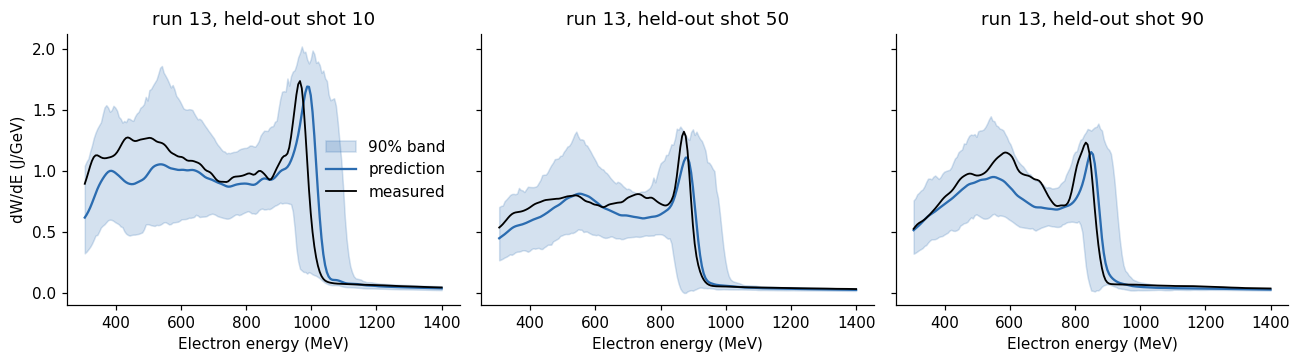

In [10]:
RAW = ROOT / "data" / "raw"
if not (RAW / "train_data_20220609.pkl").exists():
    print("Gemini data not found - put the Zenodo 7510352 files in data/raw/ to enable this section.")
else:
    from mlsfqed.beam_model.twopart import PeakBeamModel, RawFeaturiser
    from mlsfqed.data.gemini import load_all, physical_spectra, time_ordered_split
    d = load_all(); Eg, Y = d["E_MeV"], physical_spectra(d)
    tr, te = time_ordered_split(d)
    rf = RawFeaturiser().fit(d, tr)
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        bmod = PeakBeamModel(Eg, seed=0, shape="sqrt_edge", gp_blend=("position",)).fit(rf.transform(d, tr), Y[tr]).calibrate()
    print(f"trained in {time.time() - t0:.0f} s on {tr.sum()} shots")
    Xte, Yte = rf.transform(d, te), Y[te]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
    for ax, i in zip(axes, (10, 50, 90)):
        samp = bmod.sample_calibrated(Xte[i:i + 1], 200, 0)[0]
        lo, hi = np.percentile(samp, [5, 95], axis=0)
        ax.fill_between(Eg, lo, hi, color=COL["stochastic"], alpha=0.2, label="90% band")
        ax.plot(Eg, bmod.predict_point(Xte[i:i + 1])[0], color=COL["stochastic"], label="prediction")
        ax.plot(Eg, Yte[i], "k", lw=1.2, label="measured")
        ax.set(xlabel="Electron energy (MeV)", title=f"run 13, held-out shot {i}")
    axes[0].set_ylabel("dW/dE (J/GeV)"); axes[0].legend(frameon=False)
    fig.tight_layout()

## Where next

* `docs/report.md`: the full write-up; `docs/summary.md`: two pages.
* `scripts/`: one script per pipeline step (see the README's *Reproduce* section), e.g. `infer_los2024.py` and `compare_models.py` for the full inference on all shots, and the recovery tests with held-out Ptarmigan runs.
* `mlsfqed.surrogate.api.Surrogate`: use the surrogate in your own analysis (stay inside `s.ranges`).